# 07b. 적정가 기반 상대괴리와 이후 상대 상승 (재분석, ml-engineer)

## 질문
- **07-1:** 모형 가격(적정가)보다 낮은 동이 이후 실제로 더 많이 상승했는가? 정확히는, 동×분기 상대괴리를 넣으면 다음 기간 "서울 적격 동 중위보다 더 오른 동"을 분류하는 성능(AUC)이 좋아지는가?

## 방법과 지표
- **B1 트랙 H(과거 시점 재현 가능 괴리):** 분기 q마다 q−3~q 네 분기 거래로 적정가 모형(`log_ppa` ~ 면적·연식·층 + 구·분기)을 학습하고, `dong_id` GroupKFold(5) out-of-fold 예측의 잔차(실제 − 예측) 중앙값을 동×분기 괴리로 쓴다(분기 거래 10건 이상). 모형(HistGB vs Ridge 구간 더미)은 2019~2020 창의 그룹 CV MAE로 고른다.
- **B2 예측력 검증(07-1):** 동×분기 보정 가격(거래별 `log_ppa` − 면적·연식·층 구간 효과의 중앙값)의 s+a→s+b 변화가 그 분기 적격 동 중위보다 크면 1. 특징은 괴리, 동 보정 가격 모멘텀(s−1→s, s−4→s), 거래 수 로그, 평균 연식, 연식 30년 이상 비중, 급지 `tier_k4`, 구, 정책 사건(서울 공통). **`dong_features` 컬럼은 하나도 쓰지 않는다.**
  - 주판정 모형(사전 고정): 로지스틱(표준화, `C=1.0`). 괴리를 넣은 모형과 뺀 모형의 AUC 차이(ΔAUC)가 핵심 비교.
  - 탐색 모형: 가우시안 NB, 결정트리(깊이 4), HistGB 분류(`max_iter=200`, `early_stopping=False`), 작은 MLP(은닉 16, `alpha=1e-3`, `max_iter=500`, `early_stopping=False`). 판정에 쓰지 않음.
  - 기준선: 다수 클래스(사전 비율), 모멘텀 단일 변수 로지스틱(1분기·4분기 모멘텀 각각).
  - 지표: AUC, Brier, 정밀도·재현율(임계 0.5), precision@k(분기별 상위 10%·20%, 기본 비율과 비교), 혼동행렬, 분기별 순위 IC(괴리와 이후 상대 변화의 Spearman), 국면별(2021 / 2022~23 / 2024~) 결과.
- **B3 트랙 C(현시점 괴리, 설명용·검증되지 않음):** 2025Q4~2026Q3(잠정 분기 포함) 거래로 트랙 H 특징 + `dong_features`(학교·학원·통근·역·버스·단지 규모·좌표)를 쓴 적정가 모형의 OOF 잔차로 동별 괴리를 계산한다. 완전 관측 동에서는 Ridge·RF·HistGB를 비교하고, 전체 동에서는 HistGB 하나만 쓴다. 동별 값은 `*_internal_only.csv`에만 저장한다.

## 검증 설계
- 적정가 OOF는 `dong_id` 기준 GroupKFold(5): 한 동의 거래는 그 동을 학습하지 않은 모형으로 예측한다(같은 동이 학습·평가에 함께 들어가지 않음을 `oof_group_check.csv`로 확인).
- B2는 확장 윈도우 워크포워드. 설계별 오프셋(특징 종료 s, 레이블 시작 s+a, 레이블 종료 s+b): 주설계 (1,2), 비교 (0,1), 4분기 (1,5). 퍼지 `s'+b ≤ s`, 평가 종료 `s+b ≤ 2026Q2`, 적격 s·s+a·s+b 거래 각 10건 이상. 첫 테스트 시점 s=2021Q1.
- **최종 정제 자료 기반 의사 실시간 검증:** 테스트 시점 s의 특징·학습 레이블은 s분기 말까지 계약된 거래로 추정한 구간 계수(빈티지 C_s)로 계산하고, 평가 레이블은 전체 표본 계수(최종 빈티지)로 고정한다.
  - 한계: 표본은 최종 `in_base_nobulk`이다. s 이후 취소된 거래는 당시 보였더라도 이미 빠져 있고, 일괄거래 판정도 최종 취소 상태 기준이며, 신고 지연도 재현하지 못한다. "당시 실제로 관측 가능했던 자료"로 한 검증이 아니다.
- 사전 판정(주설계·로지스틱만): ① ΔAUC 95% 구간(분기 블록 부트스트랩 B=999, SEED=42) > 0 ② 괴리 포함 로지스틱 AUC > 모멘텀 기준선 AUC ③ 세 국면 중 둘 이상에서 ΔAUC > 0. 모두 만족해야 "괴리가 이후 상대 상승 예측에 기여", 아니면 "확인되지 않음".

## 교재 장과 달라진 점
- **6장 로지스틱·나이브베이즈·혼동행렬**, **3장 결정트리**, **10장 MLP**(작은 구조), **5장 회귀**(Ridge 적정가), **1·2장 검증 흐름**.
- 교재의 7:3 무작위 분할·10-fold 대신 동 그룹 분할과 워크포워드(퍼지 포함)를 썼다. 같은 동·같은 기간이 학습과 평가에 섞이면 누수가 생긴다(조율안 1·3절).
- 교재 6장의 정확도(CA) 대신 AUC·Brier·precision@k를 주지표로 썼고, SMOTE·IQR 삭제는 쓰지 않았다(레이블이 중위 기준이라 균형, 이상치는 플래그 표본 사용).
- 교재 10장 MLP는 계획에 따라 `early_stopping=False` 고정 하이퍼파라미터로 돌렸다. 내부 무작위 검증 분할이 시간 누수를 만들기 때문이다(탐색 결과로만 보고).
- 회귀 적정가의 잔차를 "저평가"로 단정하지 않는다. 괴리에는 입지·학군·재건축 기대·단지 규모 등 모형에 없는 요인이 모두 들어 있다.

In [1]:
import os
import sys
import time
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import reanalysis_utils as ru

SEED = ru.SEED  # 42
OUT = ru.out_dir(ROOT, "07/07b")
plt = ru.set_korean_font()
T_NOTEBOOK = time.time()
pd.DataFrame({"package": ["python", "numpy", "pandas", "scipy", "scikit-learn", "statsmodels"],
              "version": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__,
                          sklearn.__version__, statsmodels.__version__]})

,package,version
0,python,3.13.5
1,numpy,2.4.6
2,pandas,3.0.3
3,scipy,1.17.1
4,scikit-learn,1.9.0
5,statsmodels,0.15.0


## 1. 자료
표본은 `in_base_nobulk`, 분기 단위는 2018Q1~2026Q3(2017Q4 부분 분기 제외). 분기 표기는 `YYYY-Qn`.

In [2]:
def qs(p):
    return f"{p.year}-Q{p.quarter}"


cols = ["gu", "dong_id", "contract_ym", "log_ppa", "area_m2", "age", "floor", "area_bin", "age_bin", "floor_bin",
        "in_base_nobulk"]
tx = ru.load_tx(ROOT, columns=cols)
nob = tx[tx["in_base_nobulk"]].drop(columns="in_base_nobulk")
nob["q"] = pd.to_datetime(nob["contract_ym"], format="%Y-%m").dt.to_period("Q")
Q_FIRST, Q_LAST = pd.Period("2018Q1", "Q"), pd.Period("2026Q3", "Q")
nob = nob[nob["q"] >= Q_FIRST].reset_index(drop=True)
QUARTERS = pd.period_range(Q_FIRST, Q_LAST, freq="Q")
GUS = sorted(nob["gu"].unique())
gu_groups = ru.read_csv_any(ROOT / "outputs/재검증/02/gu_groups.csv")
tier = gu_groups.set_index("gu")["tier_k4"].astype(int)
ev = ru.read_csv_any(ROOT / "outputs/재검증/06/table_event_calendar.csv")
ev["q"] = pd.to_datetime(ev["date"]).dt.to_period("Q")
pol = pd.DataFrame(index=QUARTERS)
pol["pol_any"] = [int((ev["q"] == q).any()) for q in QUARTERS]
for k, nm in [("정부 대책", "pol_gov"), ("규제지역 적용", "pol_reg"), ("토허제", "pol_lth")]:
    pol[nm] = [int(((ev["q"] == q) & (ev["kind"] == k)).sum()) for q in QUARTERS]
dq = nob.groupby(["dong_id", "q"]).agg(n=("log_ppa", "size"), mean_age=("age", "mean"),
                                       share_age30=("age", lambda a: float((a >= 30).mean()))).reset_index()
dong_gu = nob.drop_duplicates("dong_id").set_index("dong_id")["gu"]
pd.DataFrame({"n_tx": [len(nob)], "n_dong": [nob["dong_id"].nunique()], "n_gu": [len(GUS)],
              "n_dong_quarter": [len(dq)], "n_dong_quarter_ge10": [int((dq["n"] >= 10).sum())]})

,n_tx,n_dong,n_gu,n_dong_quarter,n_dong_quarter_ge10
0,502730,337,25,9887,6301


동×분기 가운데 거래 10건 이상인 칸만 괴리·적격 판정에 쓴다.

## 2. B1 트랙 H: 분기별 적정가 OOF와 동×분기 괴리
### 2-1. 모형 선택(2019~2020 창)
- HistGB: 면적·연식·층(연속) + 구·분기(범주형), `max_iter=200`, `early_stopping=False`.
- Ridge: 면적·연식·층 구간 + 구·분기 원핫, `alpha=1.0`(전처리는 학습 접힘에서만 fit).
- 평가: q분기 거래의 OOF 절대오차 평균(MAE, log ㎡당 가격). 두 모형 모두 같은 접힘.

In [3]:
GKF = GroupKFold(n_splits=5)
NUM_H = ["area_m2", "age", "floor"]


def h_design(d):
    X = d[NUM_H].astype(float).copy()
    X["gu_c"] = pd.Categorical(d["gu"], categories=GUS).codes
    X["q_c"] = d["qpos"].to_numpy()
    return X


def make_hgb_reg(n_cat_extra=0):
    n_num = len(NUM_H) + n_cat_extra
    return HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED,
                                         categorical_features=[n_num, n_num + 1] if n_cat_extra == 0 else None)


def make_ridge_h():
    ct = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["area_bin", "age_bin", "floor_bin", "gu", "qpos"])])
    return make_pipeline(ct, Ridge(alpha=1.0))


def window(q):
    d = nob[(nob["q"] >= q - 3) & (nob["q"] <= q)].reset_index(drop=True)
    d["qpos"] = (d["q"] - (q - 3)).map(lambda x: x.n).astype(int)
    return d


OOF_CHECK = []


def oof_window(q, kind, track):
    d = window(q)
    is_q = (d["q"] == q).to_numpy()
    pred = np.full(len(d), np.nan)
    for k, (tr, te) in enumerate(GKF.split(d, groups=d["dong_id"])):
        ov = len(set(d["dong_id"].iloc[tr]) & set(d["dong_id"].iloc[te]))
        OOF_CHECK.append({"track": track, "fold": f"{qs(q)}|k{k}", "n_overlap": ov})
        te_q = te[is_q[te]]
        if len(te_q) == 0:
            continue
        if kind == "hgb":
            m = make_hgb_reg().fit(h_design(d.iloc[tr]), d["log_ppa"].iloc[tr])
            pred[te_q] = m.predict(h_design(d.iloc[te_q]))
        else:
            m = make_ridge_h().fit(d.iloc[tr], d["log_ppa"].iloc[tr])
            pred[te_q] = m.predict(d.iloc[te_q])
    dd = d[is_q].copy()
    dd["pred"] = pred[is_q]
    dd["resid"] = dd["log_ppa"] - dd["pred"]
    return dd


t0 = time.time()
sel_rows, SEL_OOF = [], {}
for q in pd.period_range("2019Q1", "2020Q4", freq="Q"):
    for kind in ["hgb", "ridge"]:
        t1 = time.time()
        dd = oof_window(q, kind, f"H_select_{kind}")
        SEL_OOF[(q, kind)] = dd
        sel_rows.append({"q": qs(q), "model": kind, "mae": float(dd["resid"].abs().mean()), "n_tx": len(dd),
                         "sec": time.time() - t1})
SEL = pd.DataFrame(sel_rows)
SEL_SUM = SEL.groupby("model").agg(mae_mean=("mae", "mean"), mae_std=("mae", "std"), n_tx=("n_tx", "sum"),
                                   train_sec=("sec", "sum")).reset_index()
H_KIND = SEL_SUM.sort_values("mae_mean").iloc[0]["model"]
ru.save_chart_csv(SEL, OUT, "table_b1_model_select.csv")
print(f"모형 선택 {time.time() - t0:.0f}초, 선택: {H_KIND}")
SEL_SUM.round(4)

모형 선택 100초, 선택: hgb


,model,mae_mean,mae_std,n_tx,train_sec
0,hgb,0.2182,0.0078,154159,93.5423
1,ridge,0.2376,0.0109,154159,6.3483


2019Q1~2020Q4 여덟 창의 q분기 OOF MAE 평균이 더 낮은 모형을 트랙 H 전 기간에 쓴다(선택 기준과 창별 값은 `table_b1_model_select.csv`).

### 2-2. 전 기간 트랙 H 괴리(2019Q1~2026Q3)

In [4]:
t0 = time.time()
H_RES = []
for i, q in enumerate(pd.period_range("2019Q1", Q_LAST, freq="Q")):
    if (q, H_KIND) in SEL_OOF:
        dd = SEL_OOF[(q, H_KIND)]
        OOF_CHECK.extend([dict(r, track="H") for r in OOF_CHECK if r["track"] == f"H_select_{H_KIND}" and r["fold"].startswith(qs(q))])
    else:
        dd = oof_window(q, H_KIND, "H")
    H_RES.append(dd[["dong_id", "gu", "q", "resid"]])
    if i % 8 == 7:
        print(f"트랙 H {i + 1}개 분기 완료({qs(q)}), 누적 {time.time() - t0:.0f}초")
T_H = time.time() - t0
H_ALL = pd.concat(H_RES, ignore_index=True)
gapH = H_ALL.groupby(["dong_id", "q"]).agg(gap=("resid", "median"), n=("resid", "size")).reset_index()
gapH = gapH[gapH["n"] >= 10]
H_MAE = H_ALL.groupby("q")["resid"].apply(lambda r: r.abs().mean())
H_MAE_TAB = H_ALL.groupby("q")["resid"].agg(mae=lambda r: r.abs().mean(), n_tx="size").reset_index()
H_MAE_TAB["quarter"] = H_MAE_TAB["q"].map(qs)
ru.save_chart_csv(H_MAE_TAB[["quarter", "mae", "n_tx"]], OUT, "table_b1_oof_mae_by_quarter.csv")
pd.DataFrame({"n_quarter": [H_ALL["q"].nunique()], "n_tx": [len(H_ALL)], "oof_mae_mean": [H_MAE.mean()],
              "n_dong_quarter_gap": [len(gapH)], "gap_median": [gapH["gap"].median()],
              "gap_p10": [gapH["gap"].quantile(0.1)], "gap_p90": [gapH["gap"].quantile(0.9)], "sec": [round(T_H, 1)]})

트랙 H 8개 분기 완료(2020-Q4), 누적 0초


트랙 H 16개 분기 완료(2022-Q4), 누적 62초


트랙 H 24개 분기 완료(2024-Q4), 누적 120초


,n_quarter,n_tx,oof_mae_mean,n_dong_quarter_gap,gap_median,gap_p10,gap_p90,sec
0,31,421657,0.222867,5497,0.033054,-0.213245,0.267974,176.5


분기별 OOF MAE는 `table_b1_oof_mae_by_quarter.csv`에 있다. 괴리(로그 단위)는 "같은 구·같은 분기 창에서 면적·연식·층이 비슷한 거래보다 그 동이 얼마나 비싼가(+)/싼가(−)"이다. 입지·학군·재건축 기대·단지 규모가 모두 이 값에 들어 있다.

## 3. B2 보정 가격 빈티지(C_s)
`log_ppa ~ 구×분기 FE + 면적·연식·층 구간`(`ru.fe_ols`)을 s분기 말까지의 거래로 추정한 계수로 동×분기 보정 가격(거래별 `log_ppa` − 구간 효과의 중앙값)을 만든다. s = 2021Q1~2026Q1 각각 한 번씩, 그리고 전체 표본(최종 빈티지)으로 한 번 추정해 세 설계에 재사용한다.

In [5]:
XB = ru.dummies(nob, ru.CHAR_REFS).reset_index(drop=True)
YB = nob["log_ppa"].to_numpy()
GQ_KEY = (nob["gu"] + "|" + nob["q"].astype(str)).to_numpy()
Q_ARR = nob["q"].to_numpy()


def adj_price(s_end):
    msk = (nob["q"] <= s_end).to_numpy()
    res = ru.fe_ols(YB[msk], XB[msk].reset_index(drop=True), [GQ_KEY[msk]], clusters=None)
    beta = res["beta"].reindex(XB.columns).fillna(0.0).to_numpy()
    adj = YB[msk] - XB[msk].to_numpy() @ beta
    d = pd.DataFrame({"dong_id": nob["dong_id"].to_numpy()[msk], "q": nob["q"].to_numpy()[msk], "adj": adj})
    P = d.groupby(["dong_id", "q"])["adj"].median().unstack("q")
    return P.reindex(columns=[q for q in QUARTERS if q <= s_end])


TEST_S = pd.period_range("2021Q1", "2026Q1", freq="Q")
t0 = time.time()
PV = {s: adj_price(s) for s in TEST_S}
P_FINAL = adj_price(Q_LAST)
T_C = time.time() - t0
pd.DataFrame({"n_vintage": [len(PV)], "sec": [round(T_C, 1)], "n_dong_final": [len(P_FINAL)]})

,n_vintage,sec,n_dong_final
0,21,17.3,337


## 4. B2 특징·레이블과 워크포워드

In [6]:
DESIGNS = {"main_a1_b2": (1, 2, "주설계"), "cmp_a0_b1": (0, 1, "비교(건너뛰기 없음)"), "sens_a1_b5": (1, 5, "민감도(4분기)")}
EVAL_END = pd.Period("2026Q2", "Q")
NMAT = dq.pivot(index="dong_id", columns="q", values="n").reindex(columns=QUARTERS).fillna(0)
AGE = dq.pivot(index="dong_id", columns="q", values="mean_age").reindex(columns=QUARTERS)
S30 = dq.pivot(index="dong_id", columns="q", values="share_age30").reindex(columns=QUARTERS)
GAPM = gapH.pivot(index="dong_id", columns="q", values="gap").reindex(columns=QUARTERS)
DONGS = NMAT.index
TIER_C = [f"tier_{k}" for k in (1, 2, 3, 4)]
GU_C = [f"gu_{i:02d}" for i in range(len(GUS))]
POL_C = ["pol_any", "pol_gov", "pol_reg", "pol_lth"]
BASE_F = ["mom1", "mom4", "log_n", "mean_age", "share_age30"] + TIER_C + GU_C + POL_C
FEAT_WITH = ["gap"] + BASE_F
FEAT_WITHOUT = BASE_F
DONG_FEATURE_COLS = set(pd.read_parquet(ROOT / "outputs/재검증/00_정제/dong_features.parquet").columns) - {"gu", "dong", "dong_id"}
assert not (set(FEAT_WITH) & DONG_FEATURE_COLS), "B2 특징에 dong_features 컬럼이 들어감"


def rows_at(P, s, a, b, label_P=None):
    """분기 s의 동 행: 특징(P 기준), 적격 여부, 레이블(label_P 기준, 없으면 NaN)."""
    if s - 4 not in P.columns or s not in P.columns:
        return None
    df = pd.DataFrame(index=DONGS)
    df["gap"] = GAPM[s].reindex(DONGS)
    df["mom1"] = (P[s] - P[s - 1]).reindex(DONGS)
    df["mom4"] = (P[s] - P[s - 4]).reindex(DONGS)
    n = NMAT[s]
    df["log_n"] = np.log(n.where(n > 0))
    df["mean_age"], df["share_age30"] = AGE[s], S30[s]
    gu = dong_gu.reindex(DONGS)
    for k in (1, 2, 3, 4):
        df[f"tier_{k}"] = (gu.map(tier) == k).astype(float)
    for i, g in enumerate(GUS):
        df[f"gu_{i:02d}"] = (gu == g).astype(float)
    for c in POL_C:
        df[c] = float(pol.loc[s, c])
    cnt_ok = (NMAT[s] >= 10)
    for off in {a, b}:
        if s + off in NMAT.columns:
            cnt_ok &= NMAT[s + off] >= 10
        else:
            cnt_ok &= False
    df["cnt_ok"] = cnt_ok
    df["mom_ok"] = df[["mom1", "mom4", "gap"]].notna().all(axis=1)
    df["elig"] = df["cnt_ok"] & df["mom_ok"]
    df["chg"] = np.nan
    if label_P is not None and (s + b) in label_P.columns:
        df["chg"] = (label_P[s + b] - label_P[s + a]).reindex(DONGS)
    e = df[df["elig"]].copy()
    if e["chg"].notna().all() and len(e):
        e["y"] = (e["chg"] > e["chg"].median()).astype(int)
        e["y30"] = (e["chg"] > e["chg"].quantile(0.7)).astype(int)
    else:
        e["y"], e["y30"] = np.nan, np.nan
    e["q"] = s
    return e.reset_index().rename(columns={"index": "dong_id"}), int((df["cnt_ok"] & ~df["mom_ok"]).sum())


def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))


EXPLORE = {"GaussianNB": lambda: make_pipeline(StandardScaler(), GaussianNB()),
           "결정트리(깊이4)": lambda: DecisionTreeClassifier(max_depth=4, random_state=SEED),
           "HistGB분류": lambda: HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=SEED),
           "MLP(16)": lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-3, max_iter=500,
                                                                           early_stopping=False, random_state=SEED))}


def run_design(key, label_col="y", explore=True):
    a, b, _ = DESIGNS[key]
    tests = [s for s in TEST_S if s + b <= EVAL_END]
    preds, folds, coefs = [], [], []
    timing = {}
    for s in tests:
        P = PV[s]
        tr_parts, n_mom_drop = [], 0
        for sp in [q for q in QUARTERS if q >= pd.Period("2019Q1", "Q") and q + b <= s]:
            r = rows_at(P, sp, a, b, label_P=P)
            if r is not None:
                tr_parts.append(r[0])
        tr = pd.concat(tr_parts, ignore_index=True)
        te, n_drop = rows_at(P, s, a, b, label_P=P_FINAL)
        out = te[["dong_id", "q", "gap", "mom1", "mom4", "chg", "y", "y30"]].copy()
        specs = [("로지스틱", "with", logit, FEAT_WITH), ("로지스틱", "without", logit, FEAT_WITHOUT),
                 ("모멘텀1 단일", "base", logit, ["mom1"]), ("모멘텀4 단일", "base", logit, ["mom4"])]
        if explore:
            for nm, f in EXPLORE.items():
                specs += [(nm, "with", f, FEAT_WITH), (nm, "without", f, FEAT_WITHOUT)]
        for nm, sp_, f, fs in specs:
            t1 = time.time()
            m = f().fit(tr[fs], tr[label_col])
            timing[(nm, sp_)] = timing.get((nm, sp_), 0.0) + time.time() - t1
            out[f"p|{nm}|{sp_}"] = m.predict_proba(te[fs])[:, 1]
            if nm == "로지스틱" and sp_ == "with":
                coefs.append({"test_origin": qs(s), "gap_coef_std": float(m[-1].coef_[0][0])})
        out["p|다수 클래스|base"] = float(tr[label_col].mean())
        preds.append(out)
        folds.append({"design": key, "a": a, "b": b, "test_origin": qs(s), "coef_data_end": qs(s),
                      "train_label_end_max": qs((tr["q"] + b).max()), "n_train": len(tr), "n_test": len(te),
                      "n_test_excluded_missing_feature": n_drop, "label": label_col})
    return pd.concat(preds, ignore_index=True), pd.DataFrame(folds), pd.DataFrame(coefs), timing


t0 = time.time()
B2 = {}
for key in DESIGNS:
    B2[key] = run_design(key, explore=(key == "main_a1_b2"))
    print(f"{key} 완료, 누적 {time.time() - t0:.0f}초")
B2_SENS30 = run_design("main_a1_b2", label_col="y30", explore=False)
T_B2 = time.time() - t0
fold_b = pd.concat([B2[k][1] for k in DESIGNS] + [B2_SENS30[1]], ignore_index=True)
ru.save_chart_csv(fold_b, OUT, "fold_log.csv")
feat_list = pd.DataFrame([{"design": k, "spec": sp, "feature": f} for k in DESIGNS
                          for sp, fs in [("with_gap", FEAT_WITH), ("without_gap", FEAT_WITHOUT)] for f in fs])
ru.save_chart_csv(feat_list, OUT, "b2_feature_list.csv")
pd.DataFrame({"purge_ok": [bool((fold_b["train_label_end_max"] <= fold_b["test_origin"]).all())],
              "coef_ok": [bool((fold_b["coef_data_end"] <= fold_b["test_origin"]).all())],
              "dong_features_in_b2": [len(set(feat_list["feature"]) & DONG_FEATURE_COLS)],
              "n_features_with_gap": [len(FEAT_WITH)], "sec": [round(T_B2, 1)]})

main_a1_b2 완료, 누적 78초


cmp_a0_b1 완료, 누적 82초


sens_a1_b5 완료, 누적 85초


,purge_ok,coef_ok,dong_features_in_b2,n_features_with_gap,sec
0,True,True,0,39,88.8


`fold_log.csv`의 모든 행에서 학습 레이블 종료 ≤ 테스트 시점(퍼지)이고 계수 자료 종료 ≤ 테스트 시점이다. 실제 모형에 넣은 특징 목록은 `b2_feature_list.csv`이며 `dong_features` 컬럼은 0개다(`gu_00`~`gu_24`는 구 원핫, `tier_*`는 02번 급지).

In [7]:
fold_b.groupby(["design", "label"]).agg(n_origin=("test_origin", "size"), first=("test_origin", "min"), last=("test_origin", "max"),
                                        n_train_min=("n_train", "min"), n_train_max=("n_train", "max"),
                                        n_test_total=("n_test", "sum"),
                                        n_excl=("n_test_excluded_missing_feature", "sum")).reset_index()

,design,label,n_origin,first,last,n_train_min,n_train_max,n_test_total,n_excl
0,cmp_a0_b1,y,21,2021-Q1,2026-Q1,1507,4446,3132,13
1,main_a1_b2,y,20,2021-Q1,2025-Q4,1263,3798,2736,10
2,main_a1_b2,y30,20,2021-Q1,2025-Q4,1263,3798,2736,10
3,sens_a1_b5,y,17,2021-Q1,2025-Q1,686,2476,2091,8


`n_excl`은 거래 수 조건은 만족했지만 모멘텀 계산에 필요한 s−1 또는 s−4 분기 거래가 없거나 괴리가 없어 빠진 테스트 행 수다(계획에 명시되지 않은 구현 세부: 결측 대체 없이 적격에서 제외).

## 5. 지표와 사전 판정

In [8]:
B_BOOT = 999


def phase_of(q):
    return "2021" if q.year <= 2021 else ("2022~23" if q.year <= 2023 else "2024~")


def auc(y, p):
    return float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else np.nan


def prec_at_k(df, col, frac, ycol):
    hits, tot = 0, 0
    for _, g in df.groupby("q"):
        k = max(1, int(round(len(g) * frac)))
        top = g.nlargest(k, col)
        hits += int(top[ycol].sum())
        tot += k
    return hits / tot


def boot_dauc(df, c1, c2, ycol="y", seed=SEED):
    rng = np.random.default_rng(seed)
    qs_ = df["q"].unique()
    parts = {q: df[df["q"] == q] for q in qs_}
    out = []
    for _ in range(B_BOOT):
        pick = rng.choice(len(qs_), len(qs_), replace=True)
        d = pd.concat([parts[qs_[i]] for i in pick])
        out.append(auc(d[ycol], d[c1]) - auc(d[ycol], d[c2]))
    return float(np.quantile(out, 0.025)), float(np.quantile(out, 0.975))


def metrics(df, col, ycol="y"):
    y, p = df[ycol].to_numpy(), df[col].to_numpy()
    yh = (p >= 0.5).astype(int)
    tp, fp = int(((yh == 1) & (y == 1)).sum()), int(((yh == 1) & (y == 0)).sum())
    fn, tn = int(((yh == 0) & (y == 1)).sum()), int(((yh == 0) & (y == 0)).sum())
    return {"AUC": auc(y, p), "Brier": float(brier_score_loss(y, p)),
            "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan,
            "precision@10%": prec_at_k(df, col, 0.1, ycol), "precision@20%": prec_at_k(df, col, 0.2, ycol),
            "base_rate": float(y.mean()), "tp": tp, "fp": fp, "fn": fn, "tn": tn}


perf_rows = []
for key in DESIGNS:
    pr = B2[key][0]
    pr["phase"] = pr["q"].map(phase_of)
    pcols = [c for c in pr.columns if c.startswith("p|")]
    for c in pcols:
        _, nm, sp = c.split("|")
        flag = sp == "base"
        note = "기준선" if flag else ("주판정" if nm == "로지스틱" else "탐색")
        for ph, d in [("전체", pr)] + [(p, pr[pr.phase == p]) for p in ["2021", "2022~23", "2024~"]]:
            mt = metrics(d, c) if ph == "전체" else {"AUC": auc(d["y"], d[c])}
            for k, v in mt.items():
                perf_rows.append({"design": key, "model": nm, "spec": sp, "baseline_flag": flag, "h": DESIGNS[key][1] - DESIGNS[key][0],
                                  "phase": ph, "metric": k, "value": v, "ci_low": np.nan, "ci_high": np.nan,
                                  "n_pred": len(d), "n_quarter": d["q"].nunique(), "note": note})
    models_with = sorted({c.split("|")[1] for c in pcols if c.endswith("|with")})
    for nm in models_with:
        cw, co = f"p|{nm}|with", f"p|{nm}|without"
        for ph, d in [("전체", pr)] + [(p, pr[pr.phase == p]) for p in ["2021", "2022~23", "2024~"]]:
            lo, hi = boot_dauc(d, cw, co)
            perf_rows.append({"design": key, "model": nm, "spec": "with−without", "baseline_flag": False,
                              "h": DESIGNS[key][1] - DESIGNS[key][0], "phase": ph, "metric": "ΔAUC",
                              "value": auc(d["y"], d[cw]) - auc(d["y"], d[co]), "ci_low": lo, "ci_high": hi,
                              "n_pred": len(d), "n_quarter": d["q"].nunique(),
                              "note": "주판정" if nm == "로지스틱" else "탐색"})
PERF = pd.DataFrame(perf_rows)
main = PERF[(PERF.design == "main_a1_b2") & (PERF.phase == "전체")]
main[main.metric.isin(["AUC", "Brier", "precision@10%", "precision@20%", "base_rate"])].pivot_table(
    index=["model", "spec"], columns="metric", values="value").round(4)

metric                 AUC   Brier  base_rate  precision@10%  precision@20%
model      spec                                                            
GaussianNB with     0.5073  0.3649     0.4982         0.5219         0.5191
           without  0.5085  0.3643     0.4982         0.5146         0.5155
HistGB분류   with     0.4941  0.3046     0.4982         0.5109         0.5027
           without  0.5062  0.2991     0.4982         0.5073         0.5173
MLP(16)    with     0.5021  0.2857     0.4982         0.5365         0.5246
           without  0.5128  0.2789     0.4982         0.5036         0.5027
결정트리(깊이4)  with     0.4913  0.2582     0.4982         0.4891         0.5046
           without  0.4939  0.2603     0.4982         0.4745         0.5118
다수 클래스     base     0.4989  0.2500     0.4982         0.5438         0.5137
로지스틱       with     0.5072  0.2534     0.4982         0.5438         0.5319
           without  0.5108  0.2530     0.4982         0.5620         0.5246
모멘텀1 단일    base     0.4953  0.2501     0.4982         0.4781         0.4863
모멘텀4 단일    base     0.4793  0.2501     0.4982         0.5000         0.4572

주설계(특징 종료 s, 레이블 s+1→s+2)의 풀링 지표다. `with`는 괴리 포함, `without`은 괴리 제외, `base`는 기준선이다. 다수 클래스 기준선은 모든 행에 같은 확률을 주므로 AUC가 0.5다. precision@k는 기본 비율(`base_rate`)과 비교해야 한다.

In [9]:
PERF[(PERF.metric == "ΔAUC")].pivot_table(index=["design", "model"], columns="phase", values="value").round(4)

phase                    2021  2022~23   2024~      전체
design     model                                      
cmp_a0_b1  로지스틱        0.0074   0.0023 -0.0104 -0.0022
main_a1_b2 GaussianNB -0.0011  -0.0003 -0.0018 -0.0012
           HistGB분류   -0.0131  -0.0224 -0.0049 -0.0122
           MLP(16)    -0.0459  -0.0139  0.0051 -0.0107
           결정트리(깊이4)   0.0122  -0.0160 -0.0014 -0.0025
           로지스틱       -0.0015   0.0015 -0.0062 -0.0036
sens_a1_b5 로지스틱        0.0057  -0.0118 -0.0071 -0.0063

설계·모형·국면별 ΔAUC(괴리 포함 − 제외)다. 주판정은 주설계의 로지스틱 한 칸이며, 나머지는 비교·탐색이다.

In [10]:
pr = B2["main_a1_b2"][0]
dl = PERF[(PERF.design == "main_a1_b2") & (PERF.model == "로지스틱") & (PERF.metric == "ΔAUC")].set_index("phase")
auc_w = auc(pr["y"], pr["p|로지스틱|with"])
auc_m1, auc_m4 = auc(pr["y"], pr["p|모멘텀1 단일|base"]), auc(pr["y"], pr["p|모멘텀4 단일|base"])
c1 = bool(dl.loc["전체", "ci_low"] > 0)
c2 = bool(auc_w > max(auc_m1, auc_m4))
n_pos = int(sum(dl.loc[p, "value"] > 0 for p in ["2021", "2022~23", "2024~"]))
c3 = n_pos >= 2
VERD = pd.DataFrame([{"design": "main_a1_b2", "model": "로지스틱", "auc_with_gap": auc_w,
                      "auc_without_gap": auc(pr["y"], pr["p|로지스틱|without"]), "auc_momentum1": auc_m1, "auc_momentum4": auc_m4,
                      "delta_auc": dl.loc["전체", "value"], "ci_low": dl.loc["전체", "ci_low"], "ci_high": dl.loc["전체", "ci_high"],
                      **{f"delta_auc_{p}": dl.loc[p, "value"] for p in ["2021", "2022~23", "2024~"]},
                      "n_phase_positive": n_pos, "cond1": c1, "cond2": c2, "cond3": c3, "pass": bool(c1 and c2 and c3),
                      "n_pred": len(pr), "n_quarter": pr["q"].nunique(), "first_origin": qs(pr["q"].min()),
                      "last_origin": qs(pr["q"].max())}])
ru.save_chart_csv(VERD, OUT, "table_verdict.csv")
VERD.T

,0
design,main_a1_b2
model,로지스틱
auc_with_gap,0.507216
auc_without_gap,0.510778
auc_momentum1,0.495349
auc_momentum4,0.479306
delta_auc,-0.003562
ci_low,-0.01344
ci_high,0.005503
delta_auc_2021,-0.001484


위 표가 사전 판정 결과다. `pass=True`일 때만 "괴리가 이후 상대 상승 예측에 기여"라고 쓰고, 아니면 "확인되지 않음"으로 쓴다. 조건2의 모멘텀 기준선은 1분기·4분기 단일 변수 로지스틱 중 AUC가 더 높은 쪽으로 잡았다(보수적 해석).

### 5-1. 순위 IC와 로지스틱 괴리 계수

In [11]:
ic_rows = []
for key in DESIGNS:
    pr_ = B2[key][0]
    ic = pr_.groupby("q").apply(lambda g: stats.spearmanr(g["gap"], g["chg"])[0])
    ph_of_row = pr_["q"].map(phase_of)
    for ph, v in [("전체", ic)] + [(p, ic[[phase_of(q) == p for q in ic.index]]) for p in ["2021", "2022~23", "2024~"]]:
        n_pred = len(pr_) if ph == "전체" else int((ph_of_row == ph).sum())
        ic_rows.append({"design": key, "phase": ph, "ic_mean": float(v.mean()), "ic_positive_share": float((v > 0).mean()),
                        "ic_t": float(v.mean() / (v.std(ddof=1) / np.sqrt(len(v)))) if len(v) > 1 else np.nan,
                        "n_quarter": len(v), "n_pred": n_pred})
IC = pd.DataFrame(ic_rows)
ru.save_chart_csv(IC, OUT, "fig_rank_ic.csv")
COEF = B2["main_a1_b2"][2]
ru.save_chart_csv(COEF, OUT, "table_logit_gap_coef.csv")
display(IC.round(4))
pd.DataFrame({"gap_coef_std_mean": [COEF["gap_coef_std"].mean()], "share_negative": [(COEF["gap_coef_std"] < 0).mean()],
              "n_fold": [len(COEF)]})

,design,phase,ic_mean,ic_positive_share,ic_t,n_quarter,n_pred
0,main_a1_b2,전체,0.0315,0.6000,0.9444,20,2736
1,main_a1_b2,2021,0.0222,0.5000,0.1858,4,498
2,main_a1_b2,2022~23,-0.0028,0.3750,-0.0471,8,779
3,main_a1_b2,2024~,0.0704,0.8750,3.4079,8,1459
4,cmp_a0_b1,전체,-0.0540,0.4762,-1.5473,21,3132
5,cmp_a0_b1,2021,-0.1374,0.2500,-1.1537,4,584
6,cmp_a0_b1,2022~23,-0.0837,0.3750,-1.3107,8,852
7,cmp_a0_b1,2024~,0.0096,0.6667,0.4000,9,1696
8,sens_a1_b5,전체,0.0824,0.7647,1.8772,17,2091
9,sens_a1_b5,2021,-0.0293,0.5000,-0.2445,4,348


,gap_coef_std_mean,share_negative,n_fold
0,-0.066344,0.8,20


- 순위 IC는 분기마다 적격 동의 괴리와 이후 보정 가격 변화(최종 빈티지)의 Spearman 상관이다. **음수**면 "괴리가 낮은(모형보다 싼) 동이 이후 더 올랐다"는 방향이다. `ic_t`는 분기별 IC 평균 ÷ 표준오차(분기 간 독립 가정, 참고값)다.
- 로지스틱 괴리 계수(표준화)는 접힘마다 다시 추정한 값의 평균이다. 연관의 방향일 뿐 영향이 아니다.

### 5-2. 상위 30% 레이블 민감도

In [12]:
ps30 = B2_SENS30[0]
lo30, hi30 = boot_dauc(ps30, "p|로지스틱|with", "p|로지스틱|without", ycol="y30")
SENS = pd.DataFrame([{"design": "main_a1_b2", "label": "상위 30%", "auc_with": auc(ps30["y30"], ps30["p|로지스틱|with"]),
                      "auc_without": auc(ps30["y30"], ps30["p|로지스틱|without"]),
                      "auc_momentum1": auc(ps30["y30"], ps30["p|모멘텀1 단일|base"]),
                      "auc_momentum4": auc(ps30["y30"], ps30["p|모멘텀4 단일|base"]),
                      "delta_auc": auc(ps30["y30"], ps30["p|로지스틱|with"]) - auc(ps30["y30"], ps30["p|로지스틱|without"]),
                      "ci_low": lo30, "ci_high": hi30, "base_rate": ps30["y30"].mean(), "n_pred": len(ps30)}])
ru.save_chart_csv(SENS, OUT, "table_label_sensitivity.csv")
SENS.T

,0
design,main_a1_b2
label,상위 30%
auc_with,0.521664
auc_without,0.521655
auc_momentum1,0.492085
auc_momentum4,0.479996
delta_auc,0.000009
ci_low,-0.006647
ci_high,0.007383
base_rate,0.301901


상위 30% 레이블은 판정에 쓰지 않는 민감도다.

## 6. B3 트랙 C: 현시점 괴리(설명용, 검증되지 않음)
- 기준 기간 2025Q4~2026Q3(잠정 분기 포함), 비교 2025Q3~2026Q2.
- 쓰는 `dong_features` 컬럼: 학교 수(초·중·고), 학원 수(입시·보습, 국제화, 예능, 기타), 최단 통근시간, 역 거리·1km 역 수·환승역 비율, 500m 버스정류소 수, 단지 수·세대수 중앙값·대단지 비율, 좌표. 구 단위 사업체·종사자는 구와 함께 식별되지 않아 뺐다.
- 동 괴리 = 기준 기간 전체 거래 OOF 잔차의 중앙값(거래 10건 이상). 트랙 H도 같은 기간·같은 방식으로 다시 계산해 비교한다(구현 세부).

In [13]:
DF = pd.read_parquet(ROOT / "outputs/재검증/00_정제/dong_features.parquet")
DFC = ["n_school_elem", "n_school_middle", "n_school_high", "acad_exam", "acad_lang", "acad_arts", "acad_other",
       "commute_min", "subway_dist_m", "subway_n_1km", "nearest_transfer_share", "bus_n_500m",
       "apt_n_complex", "apt_households_median", "apt_large_share", "lat", "lon"]
DFI = DF.set_index("dong_id")
WINDOWS = {"2025Q4~2026Q3": (pd.Period("2025Q4", "Q"), Q_LAST), "2025Q3~2026Q2": (pd.Period("2025Q3", "Q"), pd.Period("2026Q2", "Q"))}


def cur_window(q0, q1):
    d = nob[(nob["q"] >= q0) & (nob["q"] <= q1)].reset_index(drop=True)
    d["qpos"] = (d["q"] - q0).map(lambda x: x.n).astype(int)
    f = DFI.reindex(d["dong_id"])[DFC + ["commute_missing"]].reset_index(drop=True)
    d = pd.concat([d, f], axis=1)
    d["commute_missing"] = d["commute_missing"].fillna(True).astype(float)
    return d


def c_tree_X(d, with_missing):
    X = h_design(d)
    for c in DFC:
        X[c] = d[c].astype(float)
    if with_missing:
        X["commute_missing"] = d["commute_missing"]
    return X


def make_ridge_c():
    ct = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["area_bin", "age_bin", "floor_bin", "gu", "qpos"]),
                            ("num", StandardScaler(), DFC)])
    return make_pipeline(ct, Ridge(alpha=1.0))


def make_rf_c():
    """RF: 구·분기를 학습 접힘 안에서 원핫으로 바꾸고(Ridge와 같은 방식), 면적·연식·층·동 특징은 그대로 넣는다."""
    ct = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["gu", "qpos"]),
                            ("num", "passthrough", NUM_H + DFC)])
    return make_pipeline(ct, RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=SEED, n_jobs=-1))


FOLD_MAE = []


def oof_c(d, kind, track):
    pred = np.full(len(d), np.nan)
    t1 = time.time()
    for k, (tr, te) in enumerate(GKF.split(d, groups=d["dong_id"])):
        OOF_CHECK.append({"track": track, "fold": f"k{k}",
                          "n_overlap": len(set(d["dong_id"].iloc[tr]) & set(d["dong_id"].iloc[te]))})
        ytr = d["log_ppa"].iloc[tr]
        if kind == "ridge":
            m = make_ridge_c().fit(d.iloc[tr], ytr)
            pred[te] = m.predict(d.iloc[te])
        elif kind == "rf":
            m = make_rf_c().fit(d.iloc[tr], ytr)
            pred[te] = m.predict(d.iloc[te])
        elif kind == "hgb":
            m = HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED, categorical_features=[3, 4])
            m.fit(c_tree_X(d.iloc[tr], False), ytr)
            pred[te] = m.predict(c_tree_X(d.iloc[te], False))
        elif kind == "hgb_all":
            m = HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED, categorical_features=[3, 4])
            m.fit(c_tree_X(d.iloc[tr], True), ytr)
            pred[te] = m.predict(c_tree_X(d.iloc[te], True))
        elif kind == "h":
            if H_KIND == "hgb":
                m = make_hgb_reg().fit(h_design(d.iloc[tr]), ytr)
                pred[te] = m.predict(h_design(d.iloc[te]))
            else:
                m = make_ridge_h().fit(d.iloc[tr], ytr)
                pred[te] = m.predict(d.iloc[te])
        tname, wname_ = track.split("|")
        FOLD_MAE.append({"track_model": tname, "window": wname_, "fold": k,
                         "mae": float(np.abs(d["log_ppa"].to_numpy()[te] - pred[te]).mean()), "n": len(te)})
    return d["log_ppa"].to_numpy() - pred, time.time() - t1


def fold_stats(track):
    """접힘별 MAE의 평균·표준편차(ddof=1). 풀링 OOF MAE(mae 열)와 별도로 둔다."""
    tname, wname_ = track.split("|")
    f = pd.DataFrame(FOLD_MAE)
    f = f[(f["track_model"] == tname) & (f["window"] == wname_)]["mae"]
    return {"mae_fold_mean": float(f.mean()), "mae_fold_std": float(f.std(ddof=1))}


def dong_gap(d, resid, track, pop, wname):
    g = pd.DataFrame({"dong_id": d["dong_id"], "gu": d["gu"], "r": resid}).groupby(["dong_id", "gu"]).agg(
        gap=("r", "median"), n_tx=("r", "size")).reset_index()
    g = g[g["n_tx"] >= 10]
    g["track"], g["population"], g["window"] = track, pop, wname
    return g


t0 = time.time()
gaps, cmp_rows, pop_rows, excl_rows = [], [], [], []
for wname, (q0, q1) in WINDOWS.items():
    d = cur_window(q0, q1)
    complete = d[DFC].notna().all(axis=1).to_numpy()
    dc = d[complete].reset_index(drop=True)
    dongs_all = d["dong_id"].unique()
    dongs_c = dc["dong_id"].unique()
    pop_rows += [{"window": wname, "population": "완전 관측 동", "n_dong": len(dongs_c), "n_tx": len(dc)},
                 {"window": wname, "population": "전체 동", "n_dong": len(dongs_all), "n_tx": len(d)}]
    ex = DFI.reindex(sorted(set(dongs_all) - set(dongs_c)))[DFC]
    reason = ex.isna().apply(lambda r: ",".join(c for c in DFC if r[c]), axis=1)
    for rs, n in reason.value_counts().items():
        excl_rows.append({"window": wname, "missing_columns": rs, "n_dong": int(n),
                          "n_tx": int(d["dong_id"].isin(reason[reason == rs].index).sum())})
    kinds = ["ridge", "rf", "hgb"] if wname == "2025Q4~2026Q3" else []
    res_c = {}
    for kind in kinds:
        r, sec = oof_c(dc, kind, f"C_complete_{kind}|{wname}")
        res_c[kind] = r
        cmp_rows.append({"window": wname, "population": "완전 관측 동", "model": kind, "mae": float(np.abs(r).mean()),
                         **fold_stats(f"C_complete_{kind}|{wname}"), "n_tx": len(dc), "n_dong": len(dongs_c), "train_sec": sec})
    if wname == "2025Q4~2026Q3":
        C_BEST = min(res_c, key=lambda k: np.abs(res_c[k]).mean())
    else:
        res_c[C_BEST], _ = oof_c(dc, C_BEST, f"C_complete_{C_BEST}|{wname}")
    gaps.append(dong_gap(dc, res_c[C_BEST], "C", "완전 관측 동", wname))
    r_all, sec = oof_c(d, "hgb_all", f"C_all_hgb|{wname}")
    cmp_rows.append({"window": wname, "population": "전체 동", "model": "hgb_all", "mae": float(np.abs(r_all).mean()),
                     **fold_stats(f"C_all_hgb|{wname}"), "n_tx": len(d), "n_dong": len(dongs_all), "train_sec": sec})
    gaps.append(dong_gap(d, r_all, "C", "전체 동", wname))
    r_h, sec = oof_c(d, "h", f"H_current|{wname}")
    cmp_rows.append({"window": wname, "population": "전체 동", "model": f"track_H_{H_KIND}", "mae": float(np.abs(r_h).mean()),
                     **fold_stats(f"H_current|{wname}"), "n_tx": len(d), "n_dong": len(dongs_all), "train_sec": sec})
    gH = dong_gap(d, r_h, "H", "전체 동", wname)
    gaps.append(gH)
    gaps.append(gH[gH["dong_id"].isin(dongs_c)].assign(population="완전 관측 동"))
    print(f"B3 {wname} 완료, 누적 {time.time() - t0:.0f}초")
T_B3 = time.time() - t0
GAPS = pd.concat(gaps, ignore_index=True)
CMP = pd.DataFrame(cmp_rows)
FOLDS_B3 = pd.DataFrame(FOLD_MAE)
ru.save_chart_csv(FOLDS_B3, OUT, "table_b3_fold_mae.csv")
POP = pd.DataFrame(pop_rows)
EXCL = pd.DataFrame(excl_rows)
ru.save_chart_csv(CMP, OUT, "table_b3_model_compare.csv")
ru.save_chart_csv(POP, OUT, "table_b3_population.csv")
ru.save_chart_csv(EXCL, OUT, "table_b3_exclusion_reasons.csv")
display(POP)
display(EXCL)
CMP.round(4)

B3 2025Q4~2026Q3 완료, 누적 118초


B3 2025Q3~2026Q2 완료, 누적 146초


,window,population,n_dong,n_tx
0,2025Q4~2026Q3,완전 관측 동,272,67417
1,2025Q4~2026Q3,전체 동,317,67656
2,2025Q3~2026Q2,완전 관측 동,272,72055
3,2025Q3~2026Q2,전체 동,314,72289


,window,missing_columns,n_dong,n_tx
0,2025Q4~2026Q3,"commute_min,subway_dist_m,subway_n_1km,nearest...",25,104
1,2025Q4~2026Q3,"commute_min,apt_n_complex,apt_households_media...",16,82
2,2025Q4~2026Q3,"commute_min,subway_dist_m,subway_n_1km,nearest...",2,46
3,2025Q4~2026Q3,"apt_households_median,apt_large_share",2,7
4,2025Q3~2026Q2,"commute_min,subway_dist_m,subway_n_1km,nearest...",22,101
5,2025Q3~2026Q2,"commute_min,apt_n_complex,apt_households_media...",16,75
6,2025Q3~2026Q2,"commute_min,subway_dist_m,subway_n_1km,nearest...",2,48
7,2025Q3~2026Q2,"apt_households_median,apt_large_share",2,10


,window,population,model,mae,mae_fold_mean,mae_fold_std,n_tx,n_dong,train_sec
0,2025Q4~2026Q3,완전 관측 동,ridge,0.2407,0.2407,0.0136,67417,272,0.6845
1,2025Q4~2026Q3,완전 관측 동,rf,0.3013,0.3013,0.0317,67417,272,87.2013
2,2025Q4~2026Q3,완전 관측 동,hgb,0.2300,0.2300,0.0104,67417,272,11.9592
3,2025Q4~2026Q3,전체 동,hgb_all,0.2302,0.2302,0.0127,67656,317,8.4350
4,2025Q4~2026Q3,전체 동,track_H_hgb,0.2523,0.2523,0.0092,67656,317,9.4892
5,2025Q3~2026Q2,전체 동,hgb_all,0.2348,0.2348,0.0452,72289,314,9.9031
6,2025Q3~2026Q2,전체 동,track_H_hgb,0.2558,0.2558,0.0429,72289,314,7.6945


- 첫 표는 두 모집단의 동 수·거래 수, 둘째 표는 완전 관측 동에서 빠진 동의 결측 컬럼 조합별 동 수다.
- 셋째 표는 그룹(동) OOF MAE(log ㎡당 가격)다. `mae`는 모든 접힘의 OOF 예측을 모은 풀링 MAE이고(모형 선택 기준), `mae_fold_mean`·`mae_fold_std`는 GroupKFold 5개 평가 접힘 MAE의 평균·표준편차다(접힘별 값과 표본 수는 `table_b3_fold_mae.csv`). 모형 비교는 기준 기간 완전 관측 동에서만 하고(Ridge·RF·HistGB), 가장 낮은 MAE 모형의 OOF로 이 모집단의 괴리를 계산했다. 전체 동은 HistGB(결측 그대로, `commute_missing` 포함) 하나다.

In [14]:
GAPS_INT = GAPS[["window", "population", "track", "gu", "dong_id", "gap", "n_tx"]].copy()
GAPS_INT["rank_low_to_high"] = GAPS_INT.groupby(["window", "population", "track"])["gap"].rank(method="first").astype(int)
GAPS_INT.to_csv(OUT / "gap_current_dong_internal_only.csv", index=False, encoding="utf-8-sig")


def wmedian(v, w):
    o = np.argsort(v)
    v, w = np.asarray(v)[o], np.asarray(w)[o]
    c = np.cumsum(w)
    return float(v[np.searchsorted(c, c[-1] / 2)])


GU_AGG = (GAPS.groupby(["window", "population", "track", "gu"])
          .apply(lambda g: pd.Series({"gap_wmedian": wmedian(g["gap"], g["n_tx"]), "n_dong": len(g), "n_tx": int(g["n_tx"].sum())}))
          .reset_index())
ru.save_chart_csv(GU_AGG, OUT, "fig_gap_current_gu.csv")
corr_rows = []
for (w, pop), g in GAPS.groupby(["window", "population"]):
    wide = g.pivot_table(index="dong_id", columns="track", values="gap").dropna()
    if {"H", "C"} <= set(wide.columns):
        corr_rows.append({"window": w, "population": pop, "pearson": float(wide["H"].corr(wide["C"])),
                          "spearman": float(stats.spearmanr(wide["H"], wide["C"])[0]), "n_dong": len(wide)})
# 기준 기간 vs 비교 기간 트랙 C 괴리 안정성
for pop in ["완전 관측 동", "전체 동"]:
    g = GAPS[(GAPS.track == "C") & (GAPS.population == pop)].pivot_table(index="dong_id", columns="window", values="gap").dropna()
    corr_rows.append({"window": "2025Q4~2026Q3 vs 2025Q3~2026Q2(트랙 C)", "population": pop,
                      "pearson": float(g.iloc[:, 0].corr(g.iloc[:, 1])), "spearman": float(stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0]),
                      "n_dong": len(g)})
CORR = pd.DataFrame(corr_rows)
ru.save_chart_csv(CORR, OUT, "table_gap_track_corr.csv")
OOFC = pd.DataFrame(OOF_CHECK)[["track", "fold", "n_overlap"]]
ru.save_chart_csv(OOFC, OUT, "oof_group_check.csv")
display(CORR.round(3))
pd.DataFrame({"n_fold_checked": [len(OOFC)], "max_overlap": [int(OOFC["n_overlap"].max())]})

,window,population,pearson,spearman,n_dong
0,2025Q3~2026Q2,완전 관측 동,0.783,0.762,258
1,2025Q3~2026Q2,전체 동,0.771,0.758,264
2,2025Q4~2026Q3,완전 관측 동,0.744,0.704,258
3,2025Q4~2026Q3,전체 동,0.751,0.722,265
4,2025Q4~2026Q3 vs 2025Q3~2026Q2(트랙 C),완전 관측 동,0.821,0.791,257
5,2025Q4~2026Q3 vs 2025Q3~2026Q2(트랙 C),전체 동,0.810,0.808,263


,n_fold_checked,max_overlap
0,275,0


- 첫 표는 트랙 H(면적·연식·층·구·분기만)와 트랙 C(+ 동 특징) 동별 괴리의 상관, 그리고 두 기준 기간 사이 트랙 C 괴리의 상관이다.
- 둘째 표는 모든 OOF 접힘에서 학습·평가에 함께 들어간 `dong_id` 수의 최댓값이다(0이면 그룹 분할이 지켜짐, 접힘별 값은 `oof_group_check.csv`).
- 동별 괴리는 `gap_current_dong_internal_only.csv`(내부 검증용)에만 있고, 구별 집계는 `fig_gap_current_gu.csv`에 있다. 트랙 C 괴리는 적정가치 확정이나 향후 상승 보장이 아니며, 예측력 검증(B2)도 받지 않은 값이다.

## 7. 차트와 저장

In [15]:
perf_out = PERF.copy()
perf_out["split_type"] = "워크포워드"
ru.save_chart_csv(perf_out, OUT, "table_model_performance.csv")
dauc = PERF[(PERF.metric == "ΔAUC") & (PERF.model == "로지스틱")][["design", "phase", "value", "ci_low", "ci_high", "n_pred", "n_quarter"]]
ru.save_chart_csv(dauc.rename(columns={"value": "delta_auc"}), OUT, "fig_delta_auc_phase.csv")
auc_tab = PERF[(PERF.design == "main_a1_b2") & (PERF.metric == "AUC") & (PERF.phase == "전체")][["model", "spec", "baseline_flag", "value", "n_pred", "note"]]
auc_tab = auc_tab.rename(columns={"value": "auc"})
ru.save_chart_csv(auc_tab, OUT, "fig_auc_models.csv")

fig, ax = plt.subplots(figsize=(10, 4.8))
phases = ["전체", "2021", "2022~23", "2024~"]
dn = {"main_a1_b2": "주설계 (s+1→s+2)", "cmp_a0_b1": "비교 (s→s+1)", "sens_a1_b5": "민감도 (s+1→s+5)"}
wbar = 0.26
for i, key in enumerate(DESIGNS):
    d = dauc[dauc.design == key].set_index("phase").reindex(phases)
    x = np.arange(len(phases)) + (i - 1) * wbar
    ax.bar(x, d["value"], wbar, label=dn[key], color=["tab:blue", "tab:orange", "tab:gray"][i])
    ax.errorbar(x, d["value"], yerr=[d["value"] - d["ci_low"], d["ci_high"] - d["value"]], fmt="none", ecolor="black", capsize=3, lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(np.arange(len(phases)))
ax.set_xticklabels(["전체", "2021", "2022~23", "2024~"])
ax.set_xlabel("테스트 시점 국면")
ax.set_ylabel("ΔAUC (괴리 포함 - 제외)")
ax.set_title("로지스틱 ΔAUC: 설계·국면별 (95% 분기 블록 부트스트랩 구간)")
ax.legend(fontsize=8)
fig.text(0.01, -0.03, f"주설계 n={len(B2['main_a1_b2'][0]):,}건(동×분기), 테스트 {VERD.loc[0, 'first_origin']}~{VERD.loc[0, 'last_origin']}. "
         "자료: outputs/재검증/07/07b/fig_delta_auc_phase.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_delta_auc_phase.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4.8))
a2 = auc_tab.copy()
a2["lab"] = a2["model"] + " (" + a2["spec"].map({"with": "괴리 포함", "without": "괴리 제외", "base": "기준선"}) + ")"
a2 = a2.sort_values("auc")
col = ["gray" if b else ("tab:blue" if m == "로지스틱" else "tab:cyan") for m, b in zip(a2["model"], a2["baseline_flag"])]
ax.barh(a2["lab"], a2["auc"], color=col)
for i, v in enumerate(a2["auc"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.axvline(0.5, color="black", lw=0.8, ls="--")
ax.set_xlim(0.4, max(0.7, a2["auc"].max() + 0.03))
ax.set_xlabel("AUC (풀링, 최종 빈티지 평가 레이블)")
ax.set_title("주설계 모형·기준선 AUC (s+1→s+2 상대 상승 분류)")
fig.text(0.01, -0.03, "파랑=주판정 로지스틱, 하늘=탐색 모형, 회색=기준선. 자료: outputs/재검증/07/07b/fig_auc_models.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_auc_models.png")
plt.close(fig)
pd.DataFrame({"file": sorted(p.name for p in OUT.iterdir())})

,file
0,b2_feature_list.csv
1,fig_auc_models.csv
2,fig_auc_models.png
3,fig_delta_auc_phase.csv
4,fig_delta_auc_phase.png
5,fig_gap_current_gu.csv
6,fig_rank_ic.csv
7,fold_log.csv
8,gap_current_dong_internal_only.csv
9,meta.json


## 8. summary.csv와 meta.json

In [16]:
def ym_of(q, end=False):
    return (q.asfreq("M", how="end" if end else "start")).strftime("%Y-%m")


rows = []


def add(key, label, value, unit, n, ps, pe, split, claim, src, note):
    rows.append({"key": key, "label": label, "value": value, "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": split,
                 "claim_level": claim, "source_file": src, "note": note})


for kind in ["hgb", "ridge"]:
    r = SEL_SUM[SEL_SUM.model == kind].iloc[0]
    add(f"b1_select_mae_{kind}", f"트랙 H 적정가 {('HistGB' if kind == 'hgb' else 'Ridge(구간 더미)')} 그룹(동) OOF MAE(2019~2020 창 평균)",
        round(r["mae_mean"], 6), "log ㎡당 가격", r["n_tx"], "2019-01", "2020-12", "그룹(동)", "예측 기여도",
        "table_b1_model_select.csv", f"GroupKFold(5), 창 8개 평균(표준편차 {r['mae_std']:.4f}). 선택 모형 {H_KIND}")
add("b1_h_oof_mae_all", "트랙 H 적정가 그룹(동) OOF MAE(전 기간 분기 평균)", round(float(H_MAE.mean()), 6), "log ㎡당 가격", len(H_ALL),
    "2019-01", "2026-09", "그룹(동)", "예측 기여도", "table_b1_oof_mae_by_quarter.csv", f"모형 {H_KIND}, 분기 {H_ALL['q'].nunique()}개, q−3~q 창. 2026Q3 잠정 분기 포함")
v = VERD.iloc[0]
o1, o2 = pd.Period(v["first_origin"].replace("-", ""), "Q"), pd.Period(v["last_origin"].replace("-", ""), "Q")
ps, pe = ym_of(o1 - 4), ym_of(o2 + 2, end=True)
bn = f"테스트 시점 {v['first_origin']}~{v['last_origin']}({v['n_quarter']}개), 적격 동×분기 {int(v['n_pred']):,}건, 최종 정제 자료 기반 의사 실시간 검증, 퍼지 s'+2≤s"
add("b2_main_verdict_pass", "07-1 사전 판정 통과 여부(1=괴리가 이후 상대 상승 예측에 기여, 0=확인되지 않음)", int(v["pass"]), "0/1", v["n_pred"],
    ps, pe, "워크포워드", "예측 기여도", "table_verdict.csv",
    f"주설계(1,2)·로지스틱. 조건1 {v['cond1']}, 조건2 {v['cond2']}, 조건3 {v['cond3']}(양수 국면 {v['n_phase_positive']}/3). {bn}")
add("b2_main_auc_with_gap", "주설계 로지스틱 AUC(괴리 포함)", round(v["auc_with_gap"], 6), "AUC", v["n_pred"], ps, pe, "워크포워드", "예측 기여도",
    "table_model_performance.csv", bn)
add("b2_main_auc_without_gap", "주설계 로지스틱 AUC(괴리 제외)", round(v["auc_without_gap"], 6), "AUC", v["n_pred"], ps, pe, "워크포워드",
    "예측 기여도", "table_model_performance.csv", bn)
add("b2_main_delta_auc", "주설계 로지스틱 ΔAUC(괴리 포함 − 제외)", round(v["delta_auc"], 6), "AUC 차이", v["n_pred"], ps, pe, "워크포워드",
    "예측 기여도", "table_verdict.csv", f"95% CI {v['ci_low']:.4f}~{v['ci_high']:.4f}(분기 블록 부트스트랩 B=999, SEED=42). {bn}")
for p in ["2021", "2022~23", "2024~"]:
    dp = dauc[(dauc.design == "main_a1_b2") & (dauc.phase == p)].iloc[0]
    oq = sorted(q for q in pr["q"].unique() if phase_of(q) == p)
    pps_, ppe_ = ym_of(oq[0] - 4), ym_of(oq[-1] + DESIGNS["main_a1_b2"][1], end=True)
    add(f"b2_main_delta_auc_{ {'2021': 'p2021', '2022~23': 'p2022_23', '2024~': 'p2024'}[p] }".replace(" ", ""),
        f"주설계 로지스틱 ΔAUC(국면 {p})", round(dp["value"], 6), "AUC 차이", dp["n_pred"], pps_, ppe_, "워크포워드", "예측 기여도",
        "fig_delta_auc_phase.csv", f"95% CI {dp['ci_low']:.4f}~{dp['ci_high']:.4f}, 테스트 시점 {qs(oq[0])}~{qs(oq[-1])}({dp['n_quarter']}개). "
        "기간 시작은 모멘텀 특징(s−4), 끝은 레이블 종료(s+2)")
add("b2_main_auc_momentum1", "주설계 기준선 모멘텀(1분기) 단일 로지스틱 AUC", round(v["auc_momentum1"], 6), "AUC", v["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_model_performance.csv", "기준선")
add("b2_main_auc_momentum4", "주설계 기준선 모멘텀(4분기) 단일 로지스틱 AUC", round(v["auc_momentum4"], 6), "AUC", v["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_model_performance.csv", "기준선")
add("b2_main_auc_majority", "주설계 기준선 다수 클래스 AUC", round(auc(pr["y"], pr["p|다수 클래스|base"]), 6), "AUC", v["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_model_performance.csv",
    "기준선. 접힘마다 학습 구간 양성 비율을 모든 행에 같은 확률로 줌(접힘 안에서는 정보 없음, 풀링 AUC는 접힘 간 비율 차이로 0.5에서 조금 벗어남)")
mm = PERF[(PERF.design == "main_a1_b2") & (PERF.model == "로지스틱") & (PERF.spec == "with") & (PERF.phase == "전체")].set_index("metric")["value"]
add("b2_main_precision_at10", "주설계 로지스틱(괴리 포함) precision@10%", round(mm["precision@10%"], 6), "비율", v["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_model_performance.csv", f"분기별 상위 10%. 기본 비율 {mm['base_rate']:.4f}")
add("b2_main_brier_with_gap", "주설계 로지스틱(괴리 포함) Brier", round(mm["Brier"], 6), "Brier", v["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_model_performance.csv", "낮을수록 좋음")
for key in DESIGNS:
    ic = IC[(IC.design == key) & (IC.phase == "전체")].iloc[0]
    a, b, nm = DESIGNS[key]
    fb = fold_b[(fold_b.design == key) & (fold_b.label == "y")]
    pps = ym_of(pd.Period(fb["test_origin"].min().replace("-", ""), "Q") - 4)
    ppe = ym_of(pd.Period(fb["test_origin"].max().replace("-", ""), "Q") + b, end=True)
    add(f"b2_{key}_rank_ic", f"{nm} 분기별 순위 IC 평균(괴리 vs 이후 변화)", round(ic["ic_mean"], 6), "상관계수", ic["n_pred"], pps, ppe,
        "워크포워드", "통계적 연관", "fig_rank_ic.csv",
        f"양수 분기 비율 {ic['ic_positive_share']:.3f}, 분기 {int(ic['n_quarter'])}개, t {ic['ic_t']:.2f}(참고). 음수=괴리 낮은 동이 이후 더 오름")
    if key != "main_a1_b2":
        dk = dauc[(dauc.design == key) & (dauc.phase == "전체")].iloc[0]
        add(f"b2_{key}_delta_auc", f"{nm} 로지스틱 ΔAUC(판정에 쓰지 않음)", round(dk["value"], 6), "AUC 차이", dk["n_pred"], pps, ppe,
            "워크포워드", "예측 기여도", "fig_delta_auc_phase.csv", f"95% CI {dk['ci_low']:.4f}~{dk['ci_high']:.4f}. 비교·민감도 설계")
for nm in EXPLORE:
    de = PERF[(PERF.design == "main_a1_b2") & (PERF.model == nm) & (PERF.metric == "ΔAUC") & (PERF.phase == "전체")].iloc[0]
    aw = PERF[(PERF.design == "main_a1_b2") & (PERF.model == nm) & (PERF.spec == "with") & (PERF.metric == "AUC") & (PERF.phase == "전체")].iloc[0]
    kk = {"GaussianNB": "nb", "결정트리(깊이4)": "tree", "HistGB분류": "hgb", "MLP(16)": "mlp"}[nm]
    add(f"b2_main_explore_{kk}_auc", f"주설계 {nm} AUC(괴리 포함)", round(aw["value"], 6), "AUC", aw["n_pred"], ps, pe, "워크포워드",
        "예측 기여도", "table_model_performance.csv", f"탐색 모형(판정에 쓰지 않음). ΔAUC {de['value']:.4f}(95% CI {de['ci_low']:.4f}~{de['ci_high']:.4f})")
s30 = SENS.iloc[0]
add("b2_main_top30_delta_auc", "주설계 상위 30% 레이블 로지스틱 ΔAUC(민감도)", round(s30["delta_auc"], 6), "AUC 차이", s30["n_pred"], ps, pe,
    "워크포워드", "예측 기여도", "table_label_sensitivity.csv", f"95% CI {s30['ci_low']:.4f}~{s30['ci_high']:.4f}. 판정에 쓰지 않음")
add("b2_main_gap_coef_std_mean", "주설계 로지스틱 괴리 계수(표준화) 접힘 평균", round(float(COEF["gap_coef_std"].mean()), 6), "계수", v["n_pred"],
    ps, pe, "워크포워드", "통계적 연관", "table_logit_gap_coef.csv",
    f"접힘 {len(COEF)}개 중 음수 비율 {(COEF['gap_coef_std'] < 0).mean():.3f}. 연관의 방향이며 영향이 아님")
for _, r in CMP.iterrows():
    if r["window"] != "2025Q4~2026Q3":
        continue
    add(f"b3_mae_{r['model']}_{'complete' if r['population'] == '완전 관측 동' else 'all'}",
        (f"트랙 H 현시점 적정가(면적·연식·층·구·분기만) {r['model']} 그룹(동) OOF MAE({r['population']})" if r["model"].startswith("track_H")
         else f"트랙 C 현시점 적정가(동 특징 포함) {r['model']} 그룹(동) OOF MAE({r['population']})"),
        round(r["mae"], 6), "log ㎡당 가격", r["n_tx"],
        "2025-10", "2026-09", "그룹(동)", "통계적 연관", "table_b3_model_compare.csv",
        f"동 {int(r['n_dong'])}개, GroupKFold(5), 풀링 OOF MAE. 접힘 MAE 평균 {r['mae_fold_mean']:.4f}·표준편차 {r['mae_fold_std']:.4f}. 2026Q3 잠정 분기 포함." + (f" 완전 관측 동 최선 모형 {C_BEST}" if r["population"] == "완전 관측 동" else ""))
for _, r in POP[POP.window == "2025Q4~2026Q3"].iterrows():
    add(f"b3_n_dong_{'complete' if r['population'] == '완전 관측 동' else 'all'}", f"트랙 C 모집단 동 수({r['population']})", int(r["n_dong"]), "개",
        r["n_tx"], "2025-10", "2026-09", "없음", "단순 변화", "table_b3_population.csv",
        "완전 관측 동 = 사용한 dong_features 컬럼 결측 없음. 제외 사유는 table_b3_exclusion_reasons.csv")
cr = CORR[(CORR.window == "2025Q4~2026Q3") & (CORR.population == "전체 동")].iloc[0]
add("b3_corr_track_h_c_all", "현시점 동 괴리 상관(트랙 H vs 트랙 C, 전체 동, Spearman)", round(cr["spearman"], 6), "상관계수", cr["n_dong"],
    "2025-10", "2026-09", "그룹(동)", "통계적 연관", "table_gap_track_corr.csv", f"Pearson {cr['pearson']:.3f}. 동별 값은 내부 검증용 파일에만 있음")
summary = ru.save_summary(rows, OUT)

meta = {
    "question": "07-1: 모형 가격(적정가)보다 낮은 동이 이후 실제로 더 많이 상승했는가? (동×분기 상대괴리가 이후 상대 상승 분류 성능을 높이는가)",
    "method": "B1 트랙 H: 분기 q마다 q−3~q 거래로 적정가 모형(면적·연식·층·구·분기)을 dong_id GroupKFold(5) OOF로 예측해 동×분기 괴리(잔차 중앙값, 10건 이상) 계산. B2: 동×분기 보정 가격의 s+a→s+b 변화가 적격 동 중위보다 크면 1인 분류를 로지스틱(주판정, C=1.0)·NB·트리·HistGB·MLP(탐색)와 기준선(다수 클래스, 모멘텀 단일)으로 확장 윈도우 워크포워드 검증, 괴리 유무 ΔAUC. B3 트랙 C: 현시점(2025Q4~2026Q3) dong_features 포함 적정가 OOF 괴리(설명용).",
    "validation": "최종 정제 자료 기반 의사 실시간 검증: 테스트 시점 s의 특징·학습 레이블은 s까지 자료로 추정한 구간 계수(빈티지 C_s), 평가 레이블은 전체 표본 계수. 퍼지 s'+b≤s, 평가 종료 s+b≤2026Q2. 설계 (a,b) = 주설계 (1,2), 비교 (0,1), 4분기 (1,5).",
    "textbook_chapters": "6장 로지스틱·나이브베이즈·혼동행렬, 3장 결정트리, 10장 MLP(작은 구조), 5장 회귀(Ridge 적정가), 1·2장 검증 흐름. 무작위 분할 대신 동 그룹 분할·워크포워드(조율안 1·3절).",
    "sample_period": "거래 2018-01~2026-09(in_base_nobulk), 괴리 2019Q1~2026Q3, 주설계 테스트 시점 2021Q1~2025Q4, 현시점 괴리 2025Q4~2026Q3",
    "sample_size": f"거래 {len(nob):,}건, 동 {nob['dong_id'].nunique()}개. 주설계 적격 테스트 동×분기 {int(v['n_pred']):,}건",
    "data_files": ["outputs/재검증/00_정제/transactions.parquet", "outputs/재검증/00_정제/dong_features.parquet(B3만)",
                   "outputs/재검증/02/gu_groups.csv", "outputs/재검증/06/table_event_calendar.csv"],
    "verdict": "괴리가 이후 상대 상승 예측에 기여" if v["pass"] else "확인되지 않음",
    "limitations": [
        "최종 정제 자료 기반 의사 실시간 검증이다. s 이후 취소된 거래는 이미 빠져 있고, 일괄거래 판정은 최종 취소 상태 기준이며, 신고 지연은 재현하지 못한다. 당시 실제로 관측 가능했던 자료로 한 검증이 아니다.",
        "적격 조건(레이블 분기 거래 10건 이상)은 미래 정보다. 거래가 많은 동만 평가 대상이 된다.",
        "괴리에는 입지·학군·재건축 기대·단지 규모 등 적정가 모형에 없는 요인이 모두 들어 있다. 괴리가 낮다고 저평가로 단정할 수 없다.",
        "동×분기 보정 가격은 거래 중앙값이라 거래 구성 잡음이 크다. 주설계는 한 분기를 건너뛰어 같은 분기 잡음이 특징·레이블에 함께 들어가지 않게 했다.",
        "트랙 C(현시점 괴리)는 현재 시점 동 특징을 쓴 설명용 값이며 예측력 검증을 받지 않았다. 적정가치 확정·향후 상승 보장이 아니다.",
        "동별 괴리 값과 순위는 내부 검증용(*_internal_only.csv)이며 발표·공개 대상이 아니다. 매수·매도 판단 근거가 아니다."],
    "seed": SEED,
    "runtime_sec": None,
}
pd.DataFrame({"n_summary_rows": [len(summary)]})

,n_summary_rows
0,34


In [17]:
T_TOTAL = time.time() - T_NOTEBOOK
meta["runtime_sec"] = round(T_TOTAL, 1)
tim = B2["main_a1_b2"][3]
meta["runtime_note"] = (f"트랙 H 괴리 {T_H:.0f}초, 보정 가격 빈티지 {T_C:.0f}초, B2 워크포워드 {T_B2:.0f}초, B3 {T_B3:.0f}초. "
                        "주설계 모형 학습 시간(전 시점 합, 초): " + ", ".join(f"{k[0]}|{k[1]} {s:.1f}" for k, s in tim.items()))
ru.save_meta(meta, OUT)
TIMING = pd.DataFrame([{"design": "main_a1_b2", "model": k[0], "spec": k[1], "train_sec_total": round(s, 2)} for k, s in tim.items()])
ru.save_chart_csv(TIMING, OUT, "table_train_time.csv")
TIMING

,design,model,spec,train_sec_total
0,main_a1_b2,로지스틱,with,0.10
1,main_a1_b2,로지스틱,without,0.09
2,main_a1_b2,모멘텀1 단일,base,0.04
3,main_a1_b2,모멘텀4 단일,base,0.04
4,main_a1_b2,GaussianNB,with,0.11
5,main_a1_b2,GaussianNB,without,0.05
6,main_a1_b2,결정트리(깊이4),with,0.11
7,main_a1_b2,결정트리(깊이4),without,0.09
8,main_a1_b2,HistGB분류,with,22.73
9,main_a1_b2,HistGB분류,without,21.73


학습 시간은 모든 테스트 시점의 합(초)이며 실행 환경에 따라 달라진다(재현 비교에서 제외).

## 결론 (위 결과 셀 기준으로 작성)
- **사전 판정(07-1, 주설계·로지스틱): "확인되지 않음"**(5절 판정 표, `table_verdict.csv`, `summary.csv`의 `b2_main_verdict_pass`).
  - 적격 동×분기 2,736건, 테스트 시점 2021Q1~2025Q4(20개 분기). 괴리를 넣은 로지스틱 AUC 0.507, 뺀 로지스틱 0.511. ΔAUC −0.004(95% 구간 −0.013~0.006)로 구간이 0을 포함했다(조건1 불충족).
  - 모멘텀 단일 기준선(AUC 0.495, 0.479)보다는 높았지만(조건2 충족), 국면별 ΔAUC가 양수인 국면은 2022~23(+0.002) 하나뿐이었다(조건3 불충족).
  - 모든 모형·기준선의 AUC가 0.479~0.513 범위로, 무작위 분류(0.5)와 거의 같았다. 이 설계와 특징으로는 "적격 동 중위보다 더 오를 동"을 가려내는 예측력이 확인되지 않았다.
- 탐색 모형(가우시안 NB, 결정트리, HistGB, MLP)도 ΔAUC가 −0.012~−0.001로 모두 0 이하였다(5절 ΔAUC 표). 판정에는 쓰지 않았다.
- 상위 30% 레이블 민감도의 ΔAUC는 0.000(95% 구간 −0.007~0.007)이었다(5-2절).
- 순위 IC(5-1절, 통계적 연관): 주설계 분기별 평균 +0.03(양수 분기 60%), 건너뛰기 없는 비교 설계 −0.05(양수 48%), 4분기 설계 +0.08(양수 76%)이었다. 건너뛰기 없는 설계에서만 음수(괴리 낮은 동이 다음 분기 더 오름)가 나온 것은, 같은 분기 거래 잡음이 괴리와 레이블 시작점에 함께 들어가는 기계적 평균회귀와 맞는 모습이다. 주설계에서 로지스틱 괴리 계수(표준화)의 접힘 평균은 −0.07로 작았다.
- 적정가 모형(2절): 2019~2020 창의 그룹(동) OOF MAE는 HistGB 0.218, Ridge 0.238(log ㎡당 가격)이라 HistGB를 트랙 H에 썼다. 전 기간 분기 평균 OOF MAE는 0.223이었다.
- 현시점 괴리(6절, 설명용·검증되지 않음): 완전 관측 동 272개에서 그룹(동) OOF MAE는 HistGB 0.230, Ridge 0.241, RF 0.301이었다. 전체 동 317개 기준 트랙 H와 트랙 C 동 괴리의 Spearman 상관은 0.72였다. 구별 집계는 `fig_gap_current_gu.csv`에 있고, 동별 값은 내부 검증용 파일에만 있다. B2 판정을 통과하지 못했으므로 이 괴리를 이후 상승 가능성의 근거로 쓸 수 없다.

## 한계
- **최종 정제 자료 기반 의사 실시간 검증**이다. s 이후 취소된 거래, 최종 기준 일괄거래 판정, 신고 지연을 재현하지 못한다.
- 적격 조건(레이블 쪽 분기 거래 10건 이상)은 미래 정보이며, 거래가 많은 동만 평가 대상이 된다.
- 괴리에는 입지·학군·재건축 기대·단지 규모 등 모형에 없는 요인이 모두 들어 있어, 낮은 괴리를 "저평가"로 단정할 수 없다.
- 트랙 C 현시점 괴리는 검증되지 않은 설명용 값이다. 동별 값과 순위는 내부 검증용이며 발표·공개 대상이 아니고, 매수·매도 판단 근거가 아니다.

## 시각화 (발표용): 07-1 괴리 검증 결과와 구별 현시점 괴리

저장한 CSV만 읽어 그린다.
1. **ΔAUC 국면별:** 주설계(특징 종료 s, 레이블 s+1→s+2) 로지스틱에서 괴리를 넣었을 때와 뺐을 때의 AUC 차이와 분기 블록 부트스트랩 95% 구간이다. 제목에 사전 판정 결과를 적었다. 예측 기여도 수준의 결과다.
2. **precision@k:** 분기마다 예측 확률 상위 10%·20% 동 가운데 실제로 "적격 동 중위보다 더 오른 동"의 비율이다. 점선(기본 비율)보다 높아야 의미가 있다.
3. **설계 비교:** 한 분기를 건너뛰지 않는 설계(s→s+1)는 괴리와 레이블 시작점이 같은 분기 거래를 공유해 기계적 평균회귀가 섞인다. 주설계·4분기 설계와 ΔAUC·순위 IC를 나란히 보여 이 차이를 확인한다. 판정은 주설계만 쓴다.
4. **구별 현시점 괴리:** 동 괴리를 구별로 거래 가중 중앙값으로 묶은 값이다(동 이름은 보이지 않음). 설명용이며 예측력 검증을 받지 않았고, 적정가치 확정이나 향후 상승 보장이 아니다.

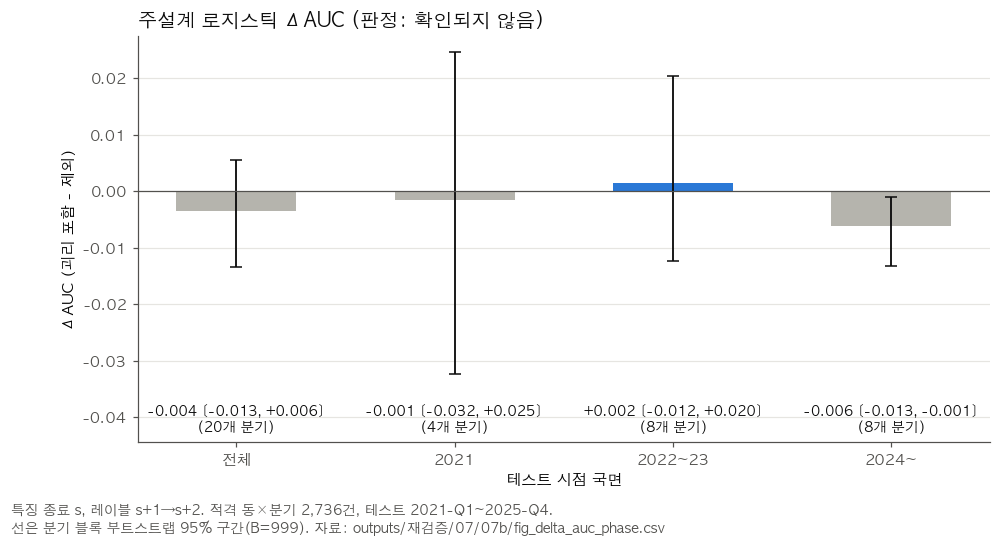

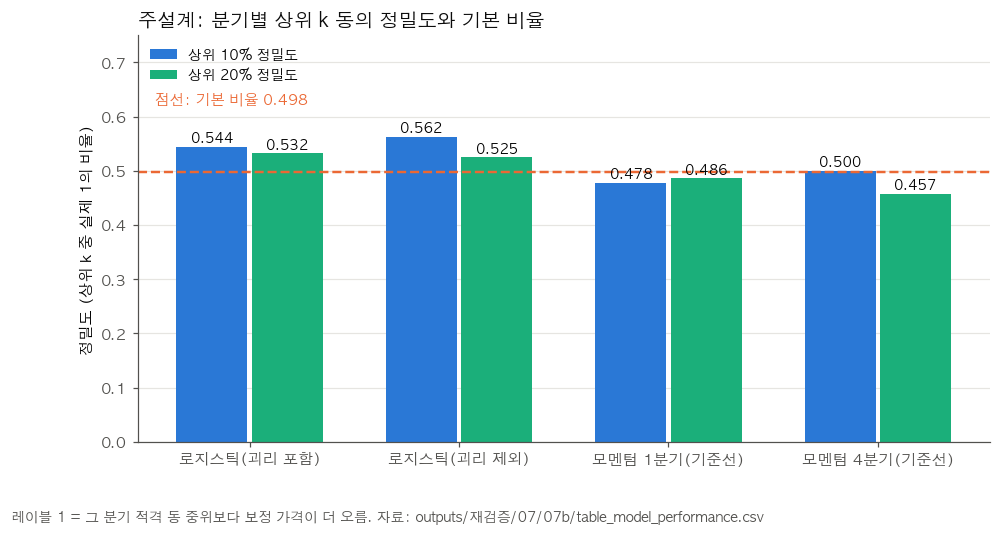

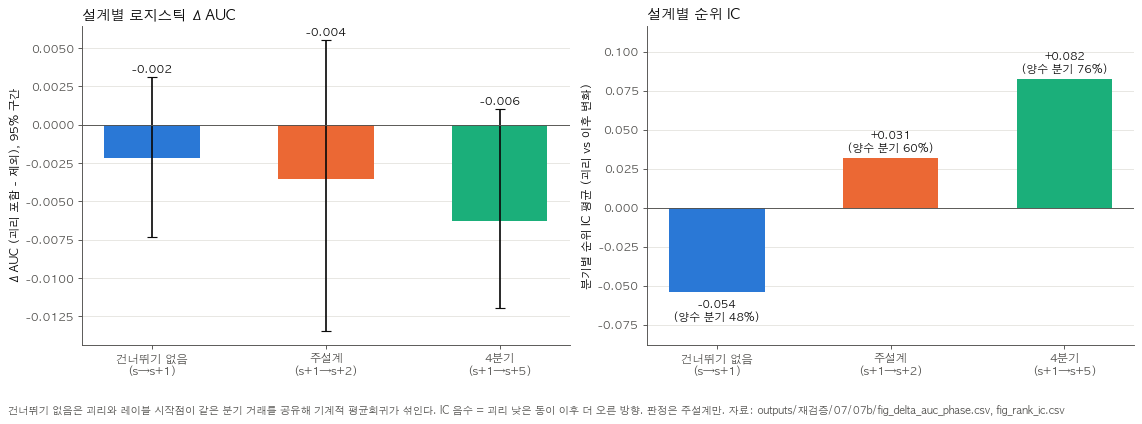

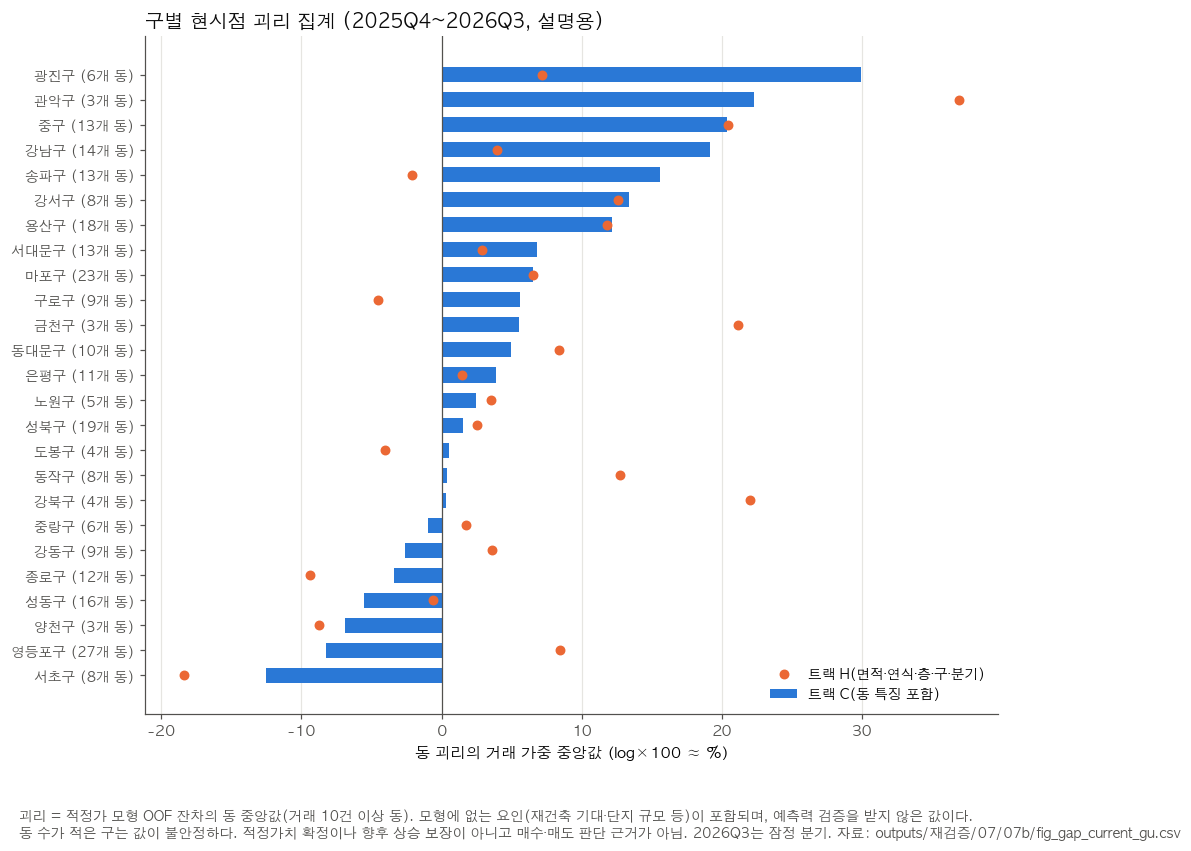

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"
MUTED = "#b5b4ad"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "07" / "07b"
verd = pd.read_csv(OUT / "table_verdict.csv").iloc[0]
dauc = pd.read_csv(OUT / "fig_delta_auc_phase.csv")
perf = pd.read_csv(OUT / "table_model_performance.csv")
PH = ["전체", "2021", "2022~23", "2024~"]

# ① 주설계 로지스틱 ΔAUC (국면별, 95% 구간)
d = dauc[dauc["design"] == "main_a1_b2"].set_index("phase").reindex(PH)
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(PH))
ax.bar(x, d["delta_auc"], 0.55, color=[SERIES[0] if v > 0 else MUTED for v in d["delta_auc"]])
ax.errorbar(x, d["delta_auc"], yerr=[d["delta_auc"] - d["ci_low"], d["ci_high"] - d["delta_auc"]], fmt="none", ecolor=INK, capsize=4, lw=1.2)
for xi, v, n, lo, hi in zip(x, d["delta_auc"], d["n_quarter"], d["ci_low"], d["ci_high"]):
    ax.annotate(f"{v:+.3f} [{lo:+.3f}, {hi:+.3f}]\n({int(n)}개 분기)", (xi, 0.02), xycoords=("data", "axes fraction"),
                ha="center", va="bottom", fontsize=9, color=INK)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x, PH)
ax.set_xlabel("테스트 시점 국면")
ax.set_ylabel("ΔAUC (괴리 포함 - 제외)")
ax.set_title(f"주설계 로지스틱 ΔAUC (판정: {'괴리가 이후 상대 상승 예측에 기여' if verd['pass'] else '확인되지 않음'})",
             loc="left", fontsize=12.5, color=INK)
style(ax)
ax.set_ylim(bottom=float(d["ci_low"].min()) - 0.012)
fig.text(0.01, -0.06, f"특징 종료 s, 레이블 s+1→s+2. 적격 동×분기 {int(verd['n_pred']):,}건, 테스트 {verd['first_origin']}~{verd['last_origin']}.\n"
         "선은 분기 블록 부트스트랩 95% 구간(B=999). 자료: outputs/재검증/07/07b/fig_delta_auc_phase.csv", fontsize=9, color=INK2)
save(fig, "viz_07b_1_delta_auc_phase.png")

# ② precision@k와 기본 비율
m = perf[(perf["design"] == "main_a1_b2") & (perf["phase"] == "전체")]
rows = [("로지스틱", "with", "로지스틱(괴리 포함)"), ("로지스틱", "without", "로지스틱(괴리 제외)"),
        ("모멘텀1 단일", "base", "모멘텀 1분기(기준선)"), ("모멘텀4 단일", "base", "모멘텀 4분기(기준선)")]
k = pd.DataFrame([{"lab": lab, **m[(m["model"] == mo) & (m["spec"] == sp)].set_index("metric")["value"][["precision@10%", "precision@20%", "base_rate"]].to_dict()}
                  for mo, sp, lab in rows])
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(k))
ax.bar(x - 0.18, k["precision@10%"], 0.34, color=SERIES[0], label="상위 10% 정밀도")
ax.bar(x + 0.18, k["precision@20%"], 0.34, color=SERIES[2], label="상위 20% 정밀도")
base = float(k["base_rate"].iloc[0])
ax.axhline(base, color=SERIES[1], lw=1.6, ls="--")
ax.text(-0.45, base + 0.12, f"점선: 기본 비율 {base:.3f}", ha="left", va="bottom", fontsize=9.5, color=SERIES[1])
for xi, a, b in zip(x, k["precision@10%"], k["precision@20%"]):
    ax.annotate(f"{a:.3f}", (xi - 0.18, a), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(f"{b:.3f}", (xi + 0.18, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x, k["lab"], fontsize=10)
ax.set_ylim(0, max(0.75, k[["precision@10%", "precision@20%"]].to_numpy().max() + 0.08))
ax.set_ylabel("정밀도 (상위 k 중 실제 1의 비율)")
ax.set_title("주설계: 분기별 상위 k 동의 정밀도와 기본 비율", loc="left", fontsize=12.5, color=INK)
ax.legend(frameon=False, fontsize=9, loc="upper left")
style(ax)
fig.text(0.01, -0.04, "레이블 1 = 그 분기 적격 동 중위보다 보정 가격이 더 오름. 자료: outputs/재검증/07/07b/table_model_performance.csv", fontsize=9, color=INK2)
save(fig, "viz_07b_2_precision_at_k.png")

# ③ 설계 비교: 건너뛰기 없음(같은 분기 잡음 공유) vs 주설계 vs 4분기
ic = pd.read_csv(OUT / "fig_rank_ic.csv")
DS = [("cmp_a0_b1", "건너뛰기 없음\n(s→s+1)"), ("main_a1_b2", "주설계\n(s+1→s+2)"), ("sens_a1_b5", "4분기\n(s+1→s+5)")]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
for i, (key, lab) in enumerate(DS):
    r = dauc[(dauc["design"] == key) & (dauc["phase"] == "전체")].iloc[0]
    a1.bar(i, r["delta_auc"], 0.55, color=SERIES[i])
    a1.errorbar(i, r["delta_auc"], yerr=[[r["delta_auc"] - r["ci_low"]], [r["ci_high"] - r["delta_auc"]]], fmt="none", ecolor=INK, capsize=4)
    a1.annotate(f"{r['delta_auc']:+.3f}", (i, r["ci_high"]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, color=INK)
    q = ic[(ic["design"] == key) & (ic["phase"] == "전체")].iloc[0]
    a2.bar(i, q["ic_mean"], 0.55, color=SERIES[i])
    a2.annotate(f"{q['ic_mean']:+.3f}\n(양수 분기 {q['ic_positive_share']:.0%})", (i, q["ic_mean"]), xytext=(0, -6 if q["ic_mean"] < 0 else 4),
                textcoords="offset points", ha="center", va="top" if q["ic_mean"] < 0 else "bottom", fontsize=9.5, color=INK)
for ax, yl, t in [(a1, "ΔAUC (괴리 포함 - 제외), 95% 구간", "설계별 로지스틱 ΔAUC"),
                  (a2, "분기별 순위 IC 평균 (괴리 vs 이후 변화)", "설계별 순위 IC")]:
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(3), [l for _, l in DS])
    ax.set_ylabel(yl)
    ax.set_title(t, loc="left", fontsize=12.5, color=INK)
    style(ax)
a2.margins(y=0.25)
fig.text(0.01, -0.06, "건너뛰기 없음은 괴리와 레이블 시작점이 같은 분기 거래를 공유해 기계적 평균회귀가 섞인다. IC 음수 = 괴리 낮은 동이 이후 더 오른 방향. "
         "판정은 주설계만. 자료: outputs/재검증/07/07b/fig_delta_auc_phase.csv, fig_rank_ic.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_07b_3_design_compare.png")

# ④ 현시점 괴리의 구별 집계(동 이름 없음)
gg = pd.read_csv(OUT / "fig_gap_current_gu.csv")
gg = gg[(gg["window"] == "2025Q4~2026Q3") & (gg["population"] == "전체 동")]
c = gg[gg["track"] == "C"].set_index("gu")
hh = gg[gg["track"] == "H"].set_index("gu").reindex(c.index)
order = c["gap_wmedian"].sort_values().index
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(order))
ax.barh(y, c.loc[order, "gap_wmedian"] * 100, color=SERIES[0], height=0.6, label="트랙 C(동 특징 포함)")
ax.scatter(hh.loc[order, "gap_wmedian"] * 100, y, color=SERIES[1], s=30, zorder=3, label="트랙 H(면적·연식·층·구·분기)")
ax.set_yticks(y, [f"{g} ({int(c.loc[g, 'n_dong'])}개 동)" for g in order], fontsize=9)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("동 괴리의 거래 가중 중앙값 (log×100 ≈ %)")
ax.set_title("구별 현시점 괴리 집계 (2025Q4~2026Q3, 설명용)", loc="left", fontsize=12.5, color=INK)
ax.legend(frameon=False, fontsize=9, loc="lower right")
style(ax, grid="x")
fig.text(0.01, -0.03, "괴리 = 적정가 모형 OOF 잔차의 동 중앙값(거래 10건 이상 동). 모형에 없는 요인(재건축 기대·단지 규모 등)이 포함되며, 예측력 검증을 받지 않은 값이다.\n"
         "동 수가 적은 구는 값이 불안정하다. 적정가치 확정이나 향후 상승 보장이 아니고 매수·매도 판단 근거가 아님. 2026Q3는 잠정 분기. 자료: outputs/재검증/07/07b/fig_gap_current_gu.csv",
         fontsize=9, color=INK2)
save(fig, "viz_07b_4_gap_by_gu.png")